In [2]:
import librosa
#from skimage import feature
import pandas as pd
import numpy as np
#import matplotlib.pyplot as plt
from scipy import signal
import soundfile as sf

In [5]:
import pandas as pd

# --------------------------------------------------
# File paths
# --------------------------------------------------

main_file = "sites.csv"
# --------------------------------------------------
# Load files
# --------------------------------------------------

df = pd.read_csv(main_file)
        

In [6]:
# Basic structure and summary
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate site IDs:", df["site.id"].duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe())

# Numeric relationships
print("\nNumeric correlations:")
display(df.select_dtypes(include=np.number).corr())

# Elevation summary
print("\nElevation range:", df["elevation"].min(), "to", df["elevation"].max())
print("Mean elevation:", df["elevation"].mean())
print("Median elevation:", df["elevation"].median())

# Highest and lowest sites
print("\nHighest sites:")
display(df.nlargest(5, "elevation")[["site.id", "cellcode", "elevation"]])

print("\nLowest sites:")
display(df.nsmallest(5, "elevation")[["site.id", "cellcode", "elevation"]])

Shape: (37, 7)

Data types:
site.id          int64
cellcode        object
elevation        int64
x.centroid       int64
y.centroid       int64
wkt.geometry    object
wkb.geometry    object
dtype: object

Missing values:
site.id         0
cellcode        0
elevation       0
x.centroid      0
y.centroid      0
wkt.geometry    0
wkb.geometry    0
dtype: int64

Duplicate rows: 0
Duplicate site IDs: 0

Descriptive statistics:


,site.id,elevation,x.centroid,y.centroid
count,37.000000,37.000000,37.000000,3.700000e+01
mean,38249.216216,510.972973,450472.972973,5.343257e+06
std,10685.793565,305.441983,52489.409771,4.804420e+04
min,14569.000000,102.000000,395500.000000,5.281500e+06
25%,25832.000000,218.000000,413500.000000,5.310500e+06
50%,43738.000000,512.000000,432500.000000,5.318500e+06
75%,45499.000000,684.000000,466500.000000,5.399500e+06
max,52006.000000,1214.000000,587500.000000,5.449500e+06



Numeric correlations:


,site.id,elevation,x.centroid,y.centroid
site.id,1.000000,0.330971,-0.532870,-0.999991
elevation,0.330971,1.000000,0.213832,-0.329057
x.centroid,-0.532870,0.213832,1.000000,0.536373
y.centroid,-0.999991,-0.329057,0.536373,1.000000



Elevation range: 102 to 1214
Mean elevation: 510.97297297297297
Median elevation: 512.0

Highest sites:


,site.id,cellcode,elevation
31,46190,1kmN5307E417,1214
35,49334,1kmN5293E439,1074
32,46435,1kmN5306E439,986
33,46874,1kmN5304E432,985
16,43323,1kmN5320E449,910



Lowest sites:


,site.id,cellcode,elevation
0,14569,1kmN5449E462,102
2,18800,1kmN5430E456,114
5,24578,1kmN5404E436,122
10,31917,1kmN5371E416,145
12,41501,1kmN5328E411,195


,site.id,cellcode,latitude,longitude,elevation
0,14569,1kmN5449E462,49.197151,8.485267,102
1,18672,1kmN5431E551,49.034229,9.704590,474
2,18800,1kmN5430E456,49.025850,8.404961,114
3,20675,1kmN5422E547,48.953595,9.648816,466
4,23718,1kmN5408E468,48.828680,8.570804,552
7,24608,1kmN5404E466,48.792592,8.543880,624
6,24606,1kmN5404E464,48.792481,8.516650,635
5,24578,1kmN5404E436,48.790252,8.135452,122
8,25175,1kmN5402E587,48.769351,10.190817,602
9,25832,1kmN5399E575,48.743939,10.026984,648


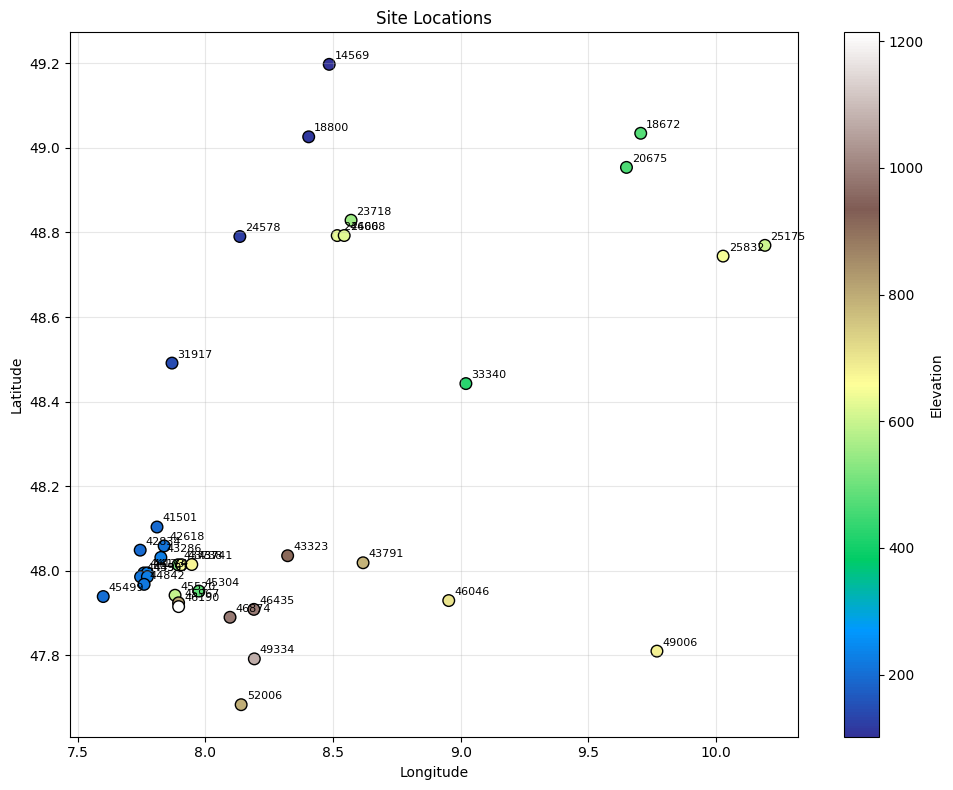

In [8]:
import re
from pyproj import Transformer

import matplotlib.pyplot as plt

# Extract the grid coordinates encoded in cellcode
cellcode_parts = df["cellcode"].str.extract(r"1kmN(?P<north_km>\d+)E(?P<east_km>\d+)")
df["cellcode_northing"] = cellcode_parts["north_km"].astype(float) * 1000 + 500
df["cellcode_easting"] = cellcode_parts["east_km"].astype(float) * 1000 + 500

# Convert ETRS89 / UTM zone 32N to WGS84 latitude/longitude
transformer = Transformer.from_crs("EPSG:25832", "EPSG:4326", always_xy=True)

df["longitude"], df["latitude"] = transformer.transform(
    df["x.centroid"].to_numpy(),
    df["y.centroid"].to_numpy()
)

# Display geographic locations
display(
    df[
        ["site.id", "cellcode", "latitude", "longitude", "elevation"]
    ].sort_values("latitude", ascending=False)
)

# Plot the spatial distribution
fig, ax = plt.subplots(figsize=(10, 8))

scatter = ax.scatter(
    df["longitude"],
    df["latitude"],
    c=df["elevation"],
    cmap="terrain",
    s=70,
    edgecolor="black"
)

for _, row in df.iterrows():
    ax.annotate(
        str(row["site.id"]),
        (row["longitude"], row["latitude"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Site Locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)

colorbar = plt.colorbar(scatter, ax=ax)
colorbar.set_label("Elevation")

plt.tight_layout()
plt.show()

# Save the GPS coordinates for use in GIS or Google Maps
df[
    ["site.id", "cellcode", "latitude", "longitude", "elevation"]
].to_csv("site_locations_gps.csv", index=False)

In [9]:
from pyproj import Geod

# Bounding box in Xeno-canto format: min_lat,min_lon,max_lat,max_lon
lat_min, lat_max = df["latitude"].min(), df["latitude"].max()
lon_min, lon_max = df["longitude"].min(), df["longitude"].max()

lat_center = (lat_min + lat_max) / 2
lon_center = (lon_min + lon_max) / 2

geod = Geod(ellps="WGS84")

# Calculate north-south and east-west distances
_, _, north_south_m = geod.inv(
    lon_center, lat_min, lon_center, lat_max
)
_, _, east_west_m = geod.inv(
    lon_min, lat_center, lon_max, lat_center
)

print(f"Original bounds: [{lat_min:.6f}, {lon_min:.6f}, {lat_max:.6f}, {lon_max:.6f}]")
print(f"Original size: {east_west_m / 1000:.1f} km east-west × "
      f"{north_south_m / 1000:.1f} km north-south")

# Expand the bounding box by a factor of 1.25 around its center
factor = 1.25

expanded_lat_min = lat_center - (lat_center - lat_min) * factor
expanded_lat_max = lat_center + (lat_max - lat_center) * factor
expanded_lon_min = lon_center - (lon_center - lon_min) * factor
expanded_lon_max = lon_center + (lon_max - lon_center) * factor

_, _, expanded_ns_m = geod.inv(
    lon_center, expanded_lat_min, lon_center, expanded_lat_max
)
_, _, expanded_ew_m = geod.inv(
    expanded_lon_min, lat_center, expanded_lon_max, lat_center
)

box = (
    f"{expanded_lat_min:.6f},"
    f"{expanded_lon_min:.6f},"
    f"{expanded_lat_max:.6f},"
    f"{expanded_lon_max:.6f}"
)

print(f"Expanded bounds: [{box}]")
print(f"Expanded size: {expanded_ew_m / 1000:.1f} km east-west × "
      f"{expanded_ns_m / 1000:.1f} km north-south")

print(f"\nXeno-canto query:\nbox:{box}")

Original bounds: [47.683669, 7.600738, 49.197151, 10.190817]
Original size: 191.6 km east-west × 168.3 km north-south
Expanded bounds: [47.494483,7.276978,49.386336,10.514577]
Expanded size: 239.5 km east-west × 210.4 km north-south

Xeno-canto query:
box:47.494483,7.276978,49.386336,10.514577
